# Customer Churn Prediction

## Google Colab setup

This notebook runs in Google Colab. Before running it:

1. Create the folder `colab-data/churn-prediction` in your Google Drive (`My Drive`).
2. Upload the data file(s) there: `WA_Fn-UseC_-Telco-Customer-Churn.csv` (Telco Customer Churn dataset).
3. Run the setup cell below and allow access to your Drive when asked.


In [ ]:
# Mount Google Drive and set the folder that holds the data
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/colab-data/churn-prediction'


In [1]:
import pandas as pd
import numpy as np
from scipy.stats import norm, skew
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# Import the dataset
dataset = pd.read_csv(f'{DATA_DIR}/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# calculate memory usage
dataset.memory_usage(deep=True).sum()

8166475

In [3]:
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
dataset.shape

(7043, 21)

In [5]:
dataset.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
dataset.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
#Recheck Column Datatypes 
    
dataset.columns.to_series().groupby(dataset.dtypes).groups

{int64: ['SeniorCitizen', 'tenure'], float64: ['MonthlyCharges'], object: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']}

In [8]:
# for each object column, calculate value counts and share of nulls

for col in dataset.select_dtypes(include=['object']):
    print(f'Column:{col}')
          
    # count for each value
    print(dataset[col].value_counts())
          
    # share of null values
    null_share = dataset[col].isnull().mean()*100
    print("Share of null values: %.2f%%"%null_share)
          
    print('\n---\n')

Column:customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
             ..
9796-MVYXX    1
2637-FKFSY    1
1552-AAGRX    1
4304-TSPVK    1
3186-AJIEK    1
Name: customerID, Length: 7043, dtype: int64
Share of null values: 0.00%

---

Column:gender
Male      3555
Female    3488
Name: gender, dtype: int64
Share of null values: 0.00%

---

Column:Partner
No     3641
Yes    3402
Name: Partner, dtype: int64
Share of null values: 0.00%

---

Column:Dependents
No     4933
Yes    2110
Name: Dependents, dtype: int64
Share of null values: 0.00%

---

Column:PhoneService
Yes    6361
No      682
Name: PhoneService, dtype: int64
Share of null values: 0.00%

---

Column:MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: MultipleLines, dtype: int64
Share of null values: 0.00%

---

Column:InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: InternetService, dtype: int64
Share of null values

In [9]:
# When converting TotalCharges into float, got a warning there is a ' '
dataset[dataset["TotalCharges"] == " "]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [10]:
# Replace Any Space With 0 and Since these 11 clients' tenure is 0 their total charges is 0 also
dataset["TotalCharges"] = dataset["TotalCharges"].replace(" ", 0)
# Convert TotalCharges into float
dataset['TotalCharges'] = dataset['TotalCharges'].astype('float64')

## Column Analysis


In [11]:
gender = dataset['gender'].value_counts(normalize=1)*100
gender.apply(lambda x: f'{x:0.2f} %')

Male      50.48 %
Female    49.52 %
Name: gender, dtype: object

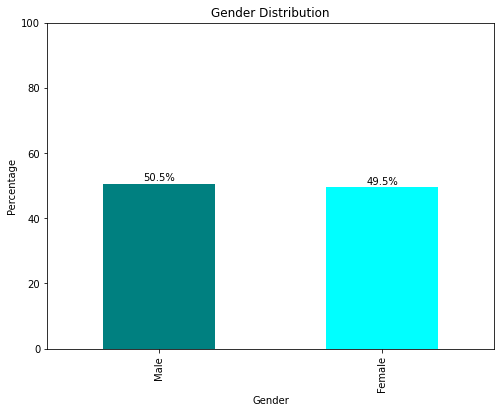

In [12]:
# Plotting the bar chart
plt.figure(figsize=(8, 6))
gender.plot(kind='bar', color=['teal', 'cyan'])  # Customize colors as needed
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Ensure the y-axis covers the full 0-100 range

# Display the percentage on top of the bars
for index, value in enumerate(gender):
    plt.text(index, value + 1, f'{value:.1f}%', ha='center')

plt.show()


In [13]:
senior = dataset['SeniorCitizen'].value_counts(normalize=1)*100
senior.apply(lambda x: f'{x:0.2f} %')

0    83.79 %
1    16.21 %
Name: SeniorCitizen, dtype: object

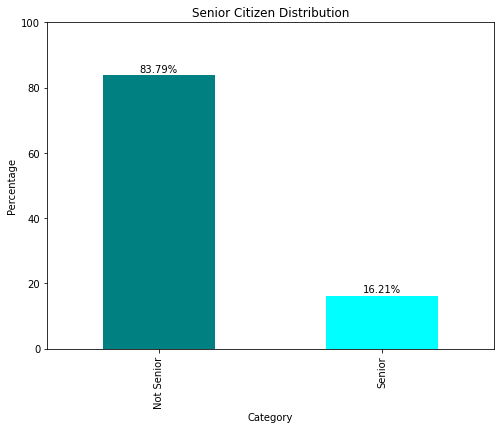

In [14]:
# Map the numerical values to the desired labels
senior.index = senior.index.map({0: 'Not Senior', 1: 'Senior'})

# Plotting the bar chart
plt.figure(figsize=(8, 6))
senior.plot(kind='bar', color=['teal', 'cyan'])  # Customize colors as needed
plt.title('Senior Citizen Distribution')
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Ensure the y-axis covers the full 0-100 range

# Display the percentage on top of the bars
for index, value in enumerate(senior):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [15]:
Dependents = dataset['Dependents'].value_counts(normalize=1)*100
Dependents.apply(lambda x: f'{x:0.2f}%')

No     70.04%
Yes    29.96%
Name: Dependents, dtype: object

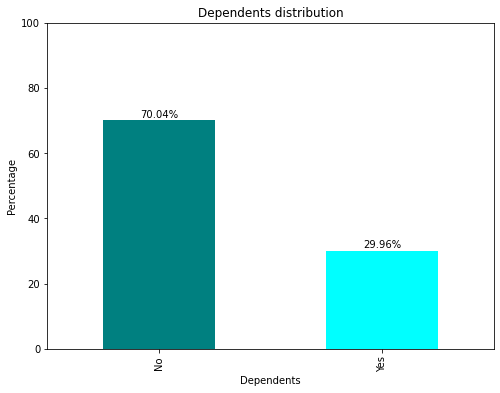

In [16]:
# Plotting the bar chart
plt.figure(figsize=(8, 6))
Dependents.plot(kind='bar', color=['teal', 'cyan'])  # Customize colors as needed
plt.title('Dependents distribution')
plt.xlabel('Dependents')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Ensure the y-axis covers the full 0-100 range

# Display the percentage on top of the bars
for index, value in enumerate(Dependents):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [17]:
dataset['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

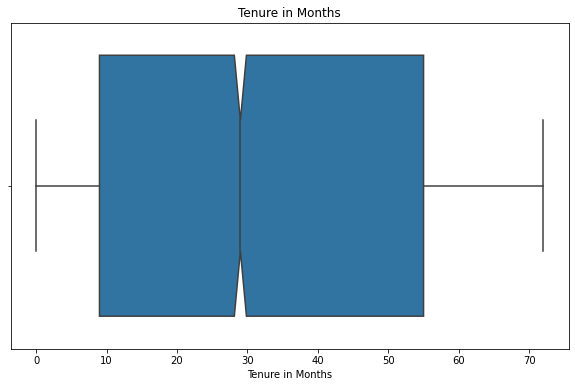

In [18]:
# boxplot for tenure
plt.figure(figsize=(10, 6))

# Creating the box plot
sns.boxplot(x=dataset['tenure'], notch=True)

# Customizing the plot
plt.title('Tenure in Months')
plt.xlabel('Tenure in Months')

# Display the plot
plt.show()

## Services distribution

In [19]:
internet_service = dataset['InternetService'].value_counts(normalize=1)*100
internet_service.apply(lambda x: f'{x:0.2f}%')

Fiber optic    43.96%
DSL            34.37%
No             21.67%
Name: InternetService, dtype: object

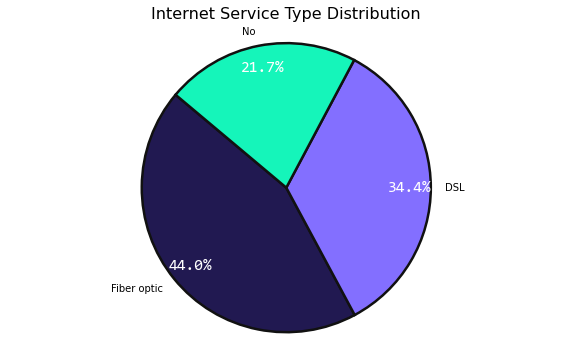

In [20]:
# Colors
colors = ['#211951', '#836FFF', '#15F5BA']  

# Create the pie chart
fig, ax = plt.subplots(figsize=(10, 6))
wedges, texts, autotexts = ax.pie(
    internet_service,
    labels=internet_service.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(edgecolor='#111', linewidth=2.5),  
    pctdistance=0.85
)

# Customize the text
plt.setp(autotexts, size=16, fontfamily='consolas', color='white')

# Equal aspect ratio ensures that pie is drawn as a circle.
ax.axis('equal')

# Title
plt.title("Internet Service Type Distribution", fontsize=16)

# Show the plot
plt.show()

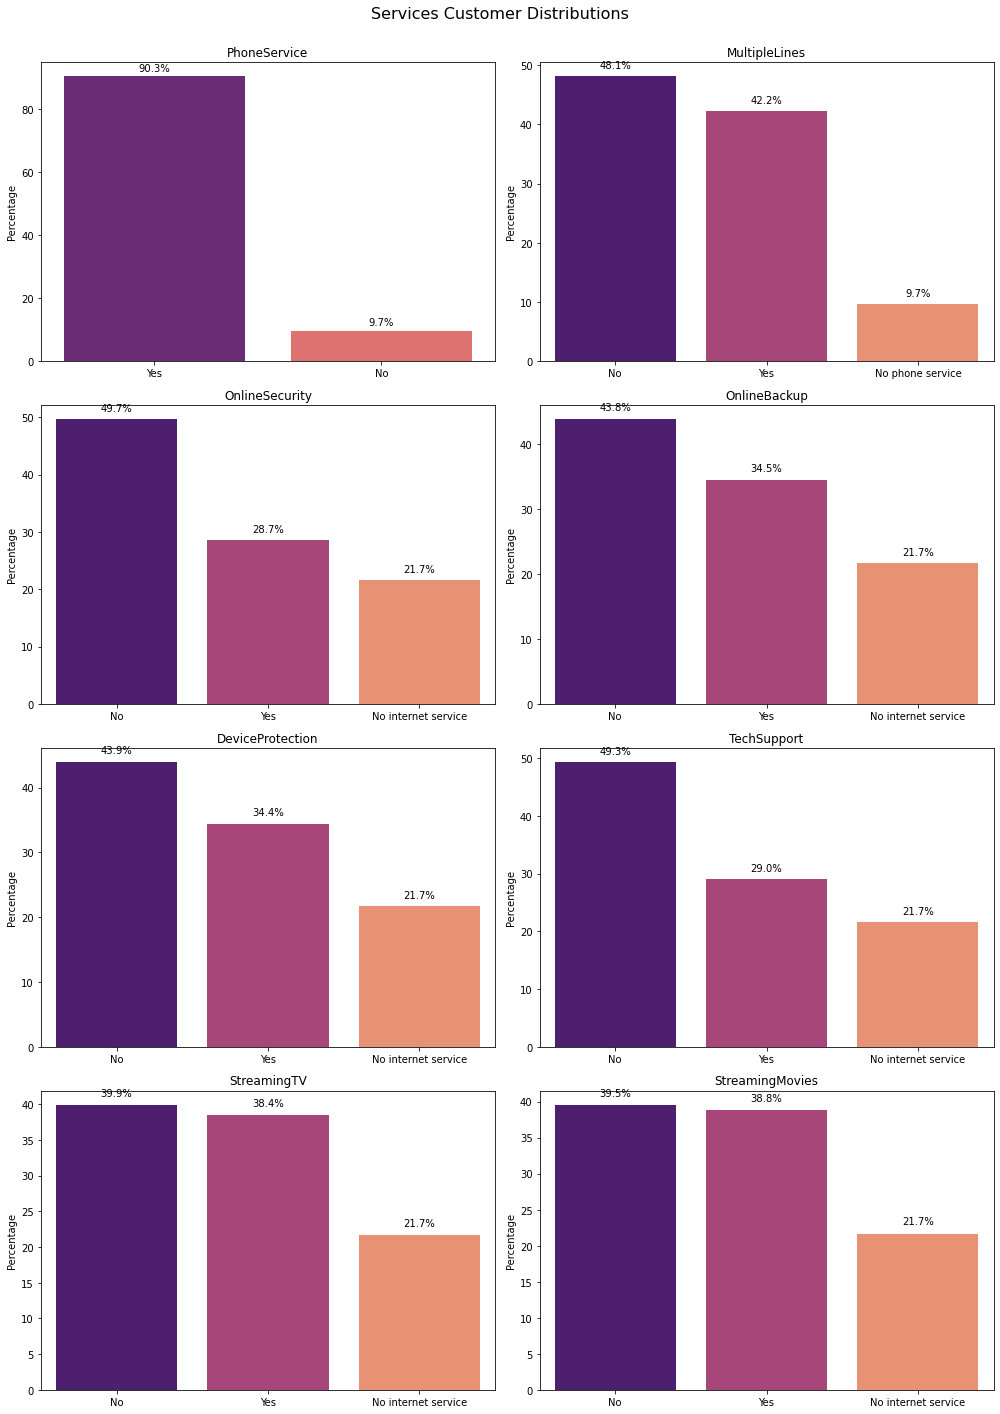

In [21]:
# List of target columns
target_columns = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

# Set up the figure and subplots
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 20))
axes = axes.flatten()

# Loop through target columns and create bar plots
for i, col in enumerate(target_columns):
    temp = dataset[col].value_counts(normalize=True) * 100
    sns.barplot(x=temp.index, y=temp.values, ax=axes[i], palette='magma')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Percentage')
    for j, value in enumerate(temp.values):
        axes[i].text(j, value + 1, f'{value:.1f}%', ha='center', va='bottom', fontsize=10, color='black')

# Adjust layout and add overall title
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.suptitle('Services Customer Distributions', fontsize=16)
plt.show()

In [22]:
contract = dataset["Contract"].value_counts(normalize=1)*100
contract.apply(lambda x: f"{x:0.2f} %")

Month-to-month    55.02 %
Two year          24.07 %
One year          20.91 %
Name: Contract, dtype: object

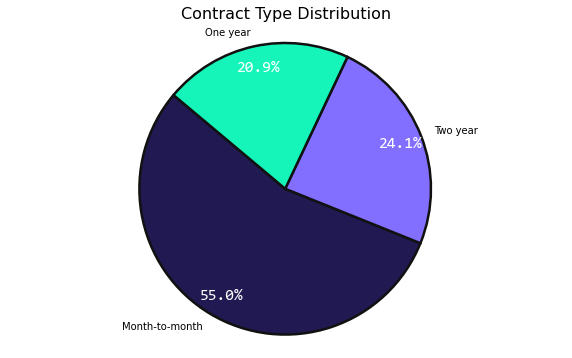

In [23]:
# Colors
colors = ['#211951', '#836FFF', '#15F5BA']  

# Create the pie chart
fig, ax = plt.subplots(figsize=(10, 6))
wedges, texts, autotexts = ax.pie(
    contract,
    labels=contract.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(edgecolor='#111', linewidth=2.5),  
    pctdistance=0.85
)

# Customize the text
plt.setp(autotexts, size=16, fontfamily='consolas', color='white')

# Equal aspect ratio ensures that pie is drawn as a circle.
ax.axis('equal')

# Title
plt.title("Contract Type Distribution", fontsize=16)

# Show the plot
plt.show()

In [24]:
payment_method = dataset['PaymentMethod'].value_counts(normalize=1)*100
payment_method.apply(lambda x: f'{x:0.2f} %')

Electronic check             33.58 %
Mailed check                 22.89 %
Bank transfer (automatic)    21.92 %
Credit card (automatic)      21.61 %
Name: PaymentMethod, dtype: object

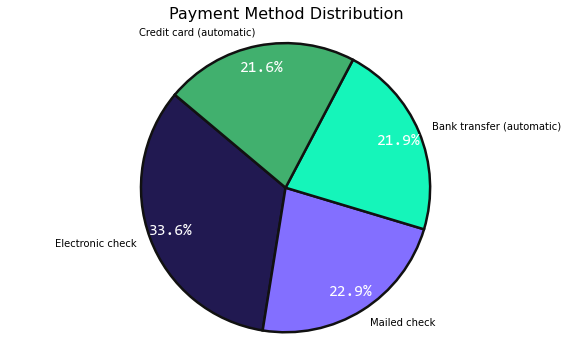

In [25]:
# Colors
colors = ['#211951', '#836FFF', '#15F5BA','#41B06E']  

# Create the pie chart
fig, ax = plt.subplots(figsize=(10, 6))
wedges, texts, autotexts = ax.pie(
    payment_method,
    labels=payment_method.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(edgecolor='#111', linewidth=2.5),  
    pctdistance=0.85
)

# Customize the text
plt.setp(autotexts, size=16, fontfamily='consolas', color='white')

# Equal aspect ratio ensures that pie is drawn as a circle.
ax.axis('equal')

# Title
plt.title("Payment Method Distribution", fontsize=16)

# Show the plot
plt.show()

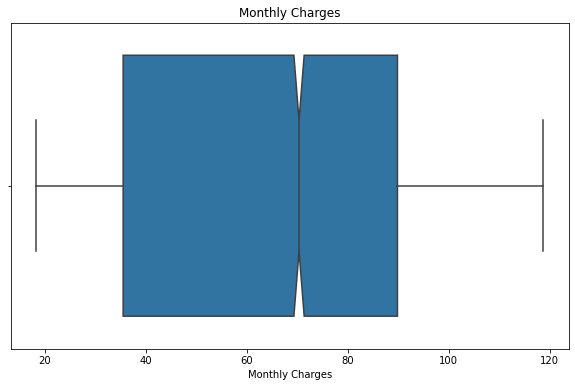

In [26]:
# boxplot for tenure
plt.figure(figsize=(10, 6))

# Creating the box plot
sns.boxplot(x=dataset['MonthlyCharges'], notch=True)

# Customizing the plot
plt.title('Monthly Charges')
plt.xlabel('Monthly Charges')

# Display the plot
plt.show()

In [27]:
dataset['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [28]:
dataset['TotalCharges'].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

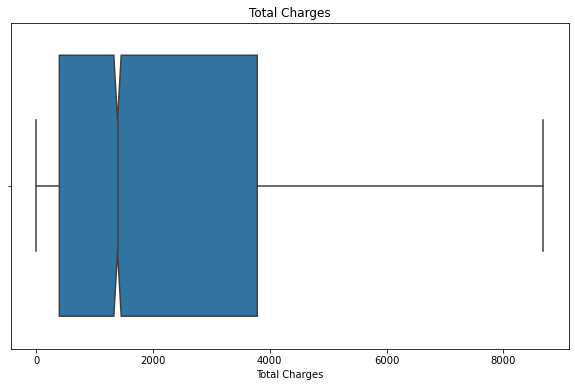

In [29]:
# boxplot for tenure
plt.figure(figsize=(10, 6))

# Creating the box plot
sns.boxplot(x=dataset['TotalCharges'], notch=True)

# Customizing the plot
plt.title('Total Charges')
plt.xlabel('Total Charges')

# Display the plot
plt.show()

In [30]:
Churn = dataset['Churn'].value_counts(normalize=1)*100
Churn.apply(lambda x: f'{x:0.2f}%')

No     73.46%
Yes    26.54%
Name: Churn, dtype: object

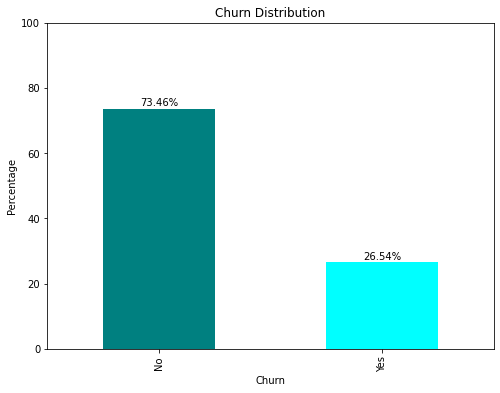

In [31]:
# Plotting the bar chart
plt.figure(figsize=(8, 6))
Churn.plot(kind='bar', color=['teal', 'cyan'])  # Customize colors as needed
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Ensure the y-axis covers the full 0-100 range

# Display the percentage on top of the bars
for index, value in enumerate(Churn):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [32]:
# Change Categorical features in 0 and 1
dataset['Partner'] = np.where(dataset['Partner'] == 'No',0,1)
dataset['Dependents'] = np.where(dataset['Dependents'] == 'No',0,1)
dataset['PhoneService'] = np.where(dataset['PhoneService'] == 'No',0,1)
dataset['PaperlessBilling'] = np.where(dataset['PaperlessBilling'] == 'No',0,1)
dataset['Churn'] = np.where(dataset['Churn'] == 'No',0,1)
dataset['MultipleLines'] = np.where(dataset['MultipleLines'] == 'No',0,
                                    np.where(dataset['MultipleLines'] == 'Yes',1,2))
dataset['OnlineSecurity'] = np.where(dataset['OnlineSecurity'] == 'No',0,
                                    np.where(dataset['OnlineSecurity'] == 'Yes',1,2))
dataset['OnlineBackup'] = np.where(dataset['OnlineBackup'] == 'No',0,
                                    np.where(dataset['OnlineBackup'] == 'Yes',1,2))
dataset['DeviceProtection'] = np.where(dataset['DeviceProtection'] == 'No',0,
                                    np.where(dataset['DeviceProtection'] == 'Yes',1,2))
dataset['TechSupport'] = np.where(dataset['TechSupport'] == 'No',0,
                                    np.where(dataset['TechSupport'] == 'Yes',1,2))
dataset['StreamingMovies'] = np.where(dataset['StreamingMovies'] == 'No',0,
                                    np.where(dataset['StreamingMovies'] == 'Yes',1,2))
dataset['StreamingTV'] = np.where(dataset['StreamingTV'] == 'No',0,
                                    np.where(dataset['StreamingTV'] == 'Yes',1,2))


In [33]:
dataset.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner               int32
Dependents            int32
tenure                int64
PhoneService          int32
MultipleLines         int32
InternetService      object
OnlineSecurity        int32
OnlineBackup          int32
DeviceProtection      int32
TechSupport           int32
StreamingTV           int32
StreamingMovies       int32
Contract             object
PaperlessBilling      int32
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int32
dtype: object

In [34]:
dataset['gender'] = np.where(dataset['gender'] == 'Male',0,1)
dataset['InternetService'] = np.where(dataset['InternetService'] == 'No',0,
                                     np.where(dataset['InternetService'] == 'Fiber optic',1,2))
dataset['Contract'] = np.where(dataset['Contract'] == 'Month-to-month',0,
                                     np.where(dataset['Contract'] == 'One year',1,2))
dataset['PaymentMethod'] = np.where(dataset['PaymentMethod'] == 'Electronic check',0,
                                     np.where(dataset['PaymentMethod'] == 'Mailed Check',1,
                                              np.where(dataset['PaymentMethod'] == 'Bank transfer (automatic)',2,3)))

In [35]:
dataset.dtypes

customerID           object
gender                int32
SeniorCitizen         int64
Partner               int32
Dependents            int32
tenure                int64
PhoneService          int32
MultipleLines         int32
InternetService       int32
OnlineSecurity        int32
OnlineBackup          int32
DeviceProtection      int32
TechSupport           int32
StreamingTV           int32
StreamingMovies       int32
Contract              int32
PaperlessBilling      int32
PaymentMethod         int32
MonthlyCharges      float64
TotalCharges        float64
Churn                 int32
dtype: object

Column: tenure
Mean: 32.37114865824223
Sigma: 24.55948102309423
Median: 29.0
Min: 0
Max: 72
Q1: 9.0
Q3: 55.0
------------------------------


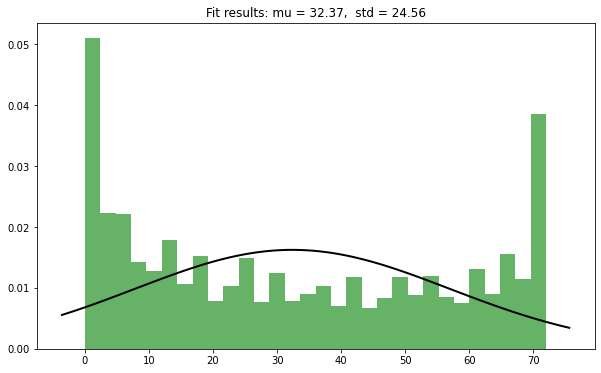

Column: MonthlyCharges
Mean: 64.76169246059922
Sigma: 30.09004709767854
Median: 70.35
Min: 18.25
Max: 118.75
Q1: 35.5
Q3: 89.85
------------------------------


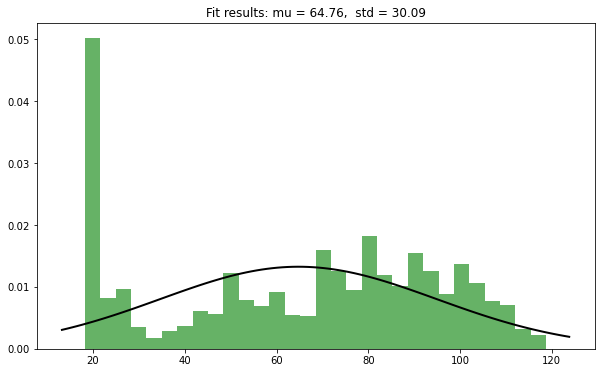

Column: TotalCharges
Mean: 2279.734303563826
Sigma: 2266.7944696890195
Median: 1394.55
Min: 0.0
Max: 8684.8
Q1: 398.55
Q3: 3786.6
------------------------------


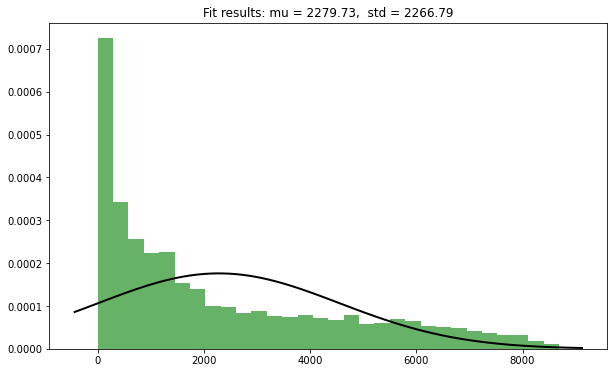

In [36]:
df_numeric = dataset[['tenure','MonthlyCharges','TotalCharges']]

for column in df_numeric:
    # Calculate statistics
    mean = df_numeric[column].mean()
    sigma = df_numeric[column].std()
    median = df_numeric[column].median()
    minimum = df_numeric[column].min()
    maximum = df_numeric[column].max()
    Q1 = df_numeric[column].quantile(0.25)
    Q3 = df_numeric[column].quantile(0.75)
    
        # Print statistics
    print(f"Column: {column}")
    print(f"Mean: {mean}")
    print(f"Sigma: {sigma}")
    print(f"Median: {median}")
    print(f"Min: {minimum}")
    print(f"Max: {maximum}")    
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(30*'-')
    
    # Plot histogram
    plt.figure(figsize=(10,6))
    plt.hist(df_numeric[column], bins=30, density=True, alpha=0.6, color='g')
    
    # Plot normal distribution with same mean and standard deviation
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mean, sigma)
    plt.plot(x, p, 'k', linewidth=2)

    title = f"Fit results: mu = {mean:.2f},  std = {sigma:.2f}"
    plt.title(title)

    plt.show()


In [37]:
# Churn distribution by gender
gender_churn = dataset.pivot_table(index="gender", columns="Churn", values="SeniorCitizen", 
                          aggfunc="count", margins=True).astype(float)

gender_churn

Churn,0,1,All
gender,,,
0,2625.0,930.0,3555.0
1,2549.0,939.0,3488.0
All,5174.0,1869.0,7043.0


In [38]:
gender_churn = pd.crosstab(index=dataset["gender"], columns=dataset["Churn"],
             values="Churn", aggfunc="count", normalize='index')*100
gender_churn

Churn,0,1
gender,,
0,73.839662,26.160338
1,73.079128,26.920872


In [39]:
# Churn distribution by Senior Status
Senior_churn = dataset.pivot_table(index="SeniorCitizen", columns="Churn", values="gender", 
                          aggfunc="count", margins=True).astype(float)

Senior_churn

Churn,0,1,All
SeniorCitizen,,,
0,4508.0,1393.0,5901.0
1,666.0,476.0,1142.0
All,5174.0,1869.0,7043.0


In [40]:
Senior_churn = pd.crosstab(index=dataset["SeniorCitizen"], columns=dataset["Churn"],
             values="Churn", aggfunc="count", normalize='index')*100
Senior_churn

Churn,0,1
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [41]:
dataset.groupby("Churn")["tenure"].describe()


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
1,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [42]:
# select only the columns for correlation
selected_columns = list(set(dataset.columns) - set(['Churn']))

# calculate correlations
corr_with_target = dataset[selected_columns + ['Churn']].corr(numeric_only=True)['Churn'][:-1]  # exclude last row because it's the correlation of target1 with itself

# create DataFrame from correlations
corr_df = pd.DataFrame({'Churn': corr_with_target})

# sort DataFrame by 'Target_2_4' in descending order
corr_df = corr_df.sort_values(by='Churn', ascending=False)

# apply conditional formatting
corr_df.style.background_gradient(cmap='coolwarm').format(precision=2)


C:\Users\User\AppData\Local\Temp\ipykernel_3340\3286455988.py:14: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  corr_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Churn
MonthlyCharges,0.19
PaperlessBilling,0.19
SeniorCitizen,0.15
InternetService,0.05
MultipleLines,0.02
PhoneService,0.01
gender,0.01
Partner,-0.15
Dependents,-0.16
TotalCharges,-0.20


In [43]:
# Calculate the correlation matrix
#corr_matrix = dataset[selected_indexes].corr(numeric_only=True)
corr_matrix = dataset.corr(numeric_only=True)

# Create a mask to ignore self-correlation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Apply the mask to the correlation matrix
corr_matrix_masked = corr_matrix.mask(mask)

# Create a DataFrame of column pairs with correlation greater than 0.7
highly_correlated_pairs = [(col, row, corr_matrix_masked[col][row]) for col in corr_matrix_masked.columns for row in corr_matrix_masked.index if abs(corr_matrix_masked[col][row]) > 0.7]

# Convert the list of tuples to a DataFrame
highly_correlated_pairs_df = pd.DataFrame(highly_correlated_pairs, columns=['Column 1', 'Column 2', 'Correlation']).sort_values(by='Correlation', ascending=False)


In [44]:
highly_correlated_pairs_df

,Column 1,Column 2,Correlation
0,tenure,TotalCharges,0.826178
17,StreamingTV,StreamingMovies,0.809608
5,OnlineSecurity,TechSupport,0.791225
12,DeviceProtection,TechSupport,0.767970
14,DeviceProtection,StreamingMovies,0.766821
13,DeviceProtection,StreamingTV,0.763279
9,OnlineBackup,TechSupport,0.754095
3,OnlineSecurity,OnlineBackup,0.751661
4,OnlineSecurity,DeviceProtection,0.749040
8,OnlineBackup,DeviceProtection,0.740604


#### Fit and visualize decision tree

In [45]:
dataset.drop('customerID', axis = 1, inplace=True)

In [46]:
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

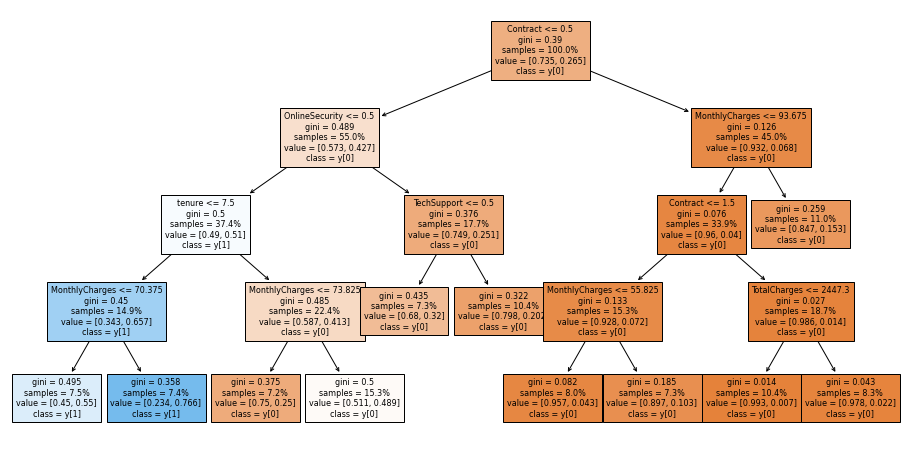

In [47]:
X = dataset.drop('Churn', axis = 1)
y = dataset['Churn']

#Initialize and fit the decision tree
clf = tree.DecisionTreeClassifier(max_depth = 4, min_samples_leaf = 500, random_state = 28)
clf.fit(X, y)

# Visualize the decision tree
fig, ax = plt.subplots(figsize=(16, 8))  # adjust size as needed

tree.plot_tree(clf, ax=ax, feature_names=X.columns, class_names=True, proportion=True, filled=True, fontsize=8)

plt.show()


## Modelling

In [48]:
!pip install -q catboost



In [49]:
!pip install -q xgboost

In [50]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#sklearn modules for Model Selection--------------------------------------

from sklearn import svm, tree, linear_model, neighbors
from sklearn import naive_bayes, ensemble, discriminant_analysis, gaussian_process
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

#sklearn modules for Model Evaluation & Improvement---------------------------
from sklearn import model_selection
from sklearn.metrics import confusion_matrix, accuracy_score,f1_score, precision_score, recall_score, fbeta_score 
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV, ShuffleSplit, KFold
from sklearn.metrics import classification_report, precision_recall_curve
from sklearn.metrics import auc, roc_auc_score, roc_curve


In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=28)

In [52]:
y_train.value_counts(normalize=1)

0    0.731452
1    0.268548
Name: Churn, dtype: float64

In [53]:
y_test.value_counts(normalize=1)

0    0.747339
1    0.252661
Name: Churn, dtype: float64

In [54]:
# Feature Scaling
sc_X = StandardScaler()
X_train = pd.DataFrame(sc_X.fit_transform(X_train),columns=X_train.columns, index=X_train.index)
X_test =pd.DataFrame(sc_X.fit_transform(X_test),columns=X_test.columns, index=X_test.index)

In [55]:
models = []

models.append(('Logistic Regression', LogisticRegression(solver='liblinear', random_state = 0,
                                                         class_weight='balanced',  n_jobs=6)))

models.append(('SVC', SVC(C=0.3, tol=0.05,  max_iter=100, kernel = 'linear', verbose=True, random_state = 0)))

models.append(('KNN', KNeighborsClassifier(n_neighbors = 100, metric = 'minkowski', p = 2,  n_jobs=6)))


models.append(('Gaussian NB', GaussianNB()))


models.append(('Decision Tree Classifier',
               DecisionTreeClassifier(max_depth=6, criterion = 'entropy', random_state = 0)))


models.append(('Random Forest', RandomForestClassifier(max_depth=5, min_samples_leaf=500,
    n_estimators=100, criterion = 'entropy', random_state = 0, n_jobs=6)))


models.append(('Gradient Boosting', GradientBoostingClassifier(max_depth=5, min_samples_leaf=500,
    n_estimators=150, criterion = 'friedman_mse', random_state = 0)))


In [56]:
#Evaluating Model Results: 

acc_results = []
auc_results = []
names = []

# set list to populate with performance results
col = ['Algorithm', 'ROC AUC Mean', 'ROC AUC STD', 
       'Accuracy Mean', 'Accuracy STD']

model_results = pd.DataFrame(columns=col)
i = 0

In [57]:
# evaluate each model using k-fold cross-validation
for name, model in models:
    print('------')
    print(name)
    kfold = model_selection.KFold(shuffle=True,
        n_splits=5, random_state=0)  # 5-fold cross-validation

    cv_acc_results = model_selection.cross_val_score(  # accuracy scoring
        model, X_train, y_train, cv=kfold, scoring='accuracy')

    cv_auc_results = model_selection.cross_val_score(  # roc_auc scoring
        model, X_train, y_train, cv=kfold, scoring='roc_auc')
    
    
    print('Train->', model_selection.cross_val_score( model, X_train, y_train, cv=kfold, scoring='roc_auc'))
    print('Test ->', model_selection.cross_val_score( model, X_test, y_test, cv=kfold, scoring='roc_auc'))

    acc_results.append(cv_acc_results)
    auc_results.append(cv_auc_results)
    names.append(name)
    model_results.loc[i] = [name,
                         round(cv_auc_results.mean()*100, 2),
                         round(cv_auc_results.std()*100, 2),
                         round(cv_acc_results.mean()*100, 2),
                         round(cv_acc_results.std()*100, 2)
                         ]
    i += 1


------
Logistic Regression


C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 

Train-> [0.85411536 0.84220624 0.84153023 0.84804009 0.83711903]
Test -> [0.84944616 0.83006026 0.85426429 0.83192374 0.82219873]
------
SVC
[LibSVM][LibSVM][LibSVM]

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklea

[LibSVM][LibSVM][LibSVM][LibSVM][LibSVM]

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklea

[LibSVM][LibSVM][LibSVM][LibSVM][LibSVM]

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklea

[LibSVM][LibSVM]Train-> [0.61826885 0.79143958 0.76371958 0.77252189 0.80130298]
[LibSVM][LibSVM][LibSVM][LibSVM][LibSVM]Test -> [0.72124271 0.72052464 0.79990628 0.30260894 0.73988724]
------
KNN


C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\svm\_base.py:284: ConvergenceWarning: Solver terminated early (max_iter=100).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Train-> [0.83752085 0.83221776 0.82196148 0.82705459 0.82764078]
Test -> [0.80661336 0.82080822 0.82743674 0.83923452 0.7803735 ]
------
Gaussian NB
Train-> [0.82429888 0.81503138 0.8053817  0.80989425 0.82026348]
Test -> [0.80291014 0.83481035 0.8253866  0.83694094 0.78301621]
------
Decision Tree Classifier
Train-> [0.83648804 0.82206245 0.82887005 0.81938527 0.82667035]
Test -> [0.76859802 0.82119816 0.79182287 0.79103354 0.74076815]
------
Random Forest
Train-> [0.84125685 0.82599706 0.81708393 0.82628956 0.83484001]
Test -> [0.5 0.5 0.5 0.5 0.5]
------
Gradient Boosting
Train-> [0.85864185 0.84131644 0.84216041 0.85189482 0.83792939]
Test -> [0.82486727 0.81517192 0.83385075 0.8102781  0.81779422]


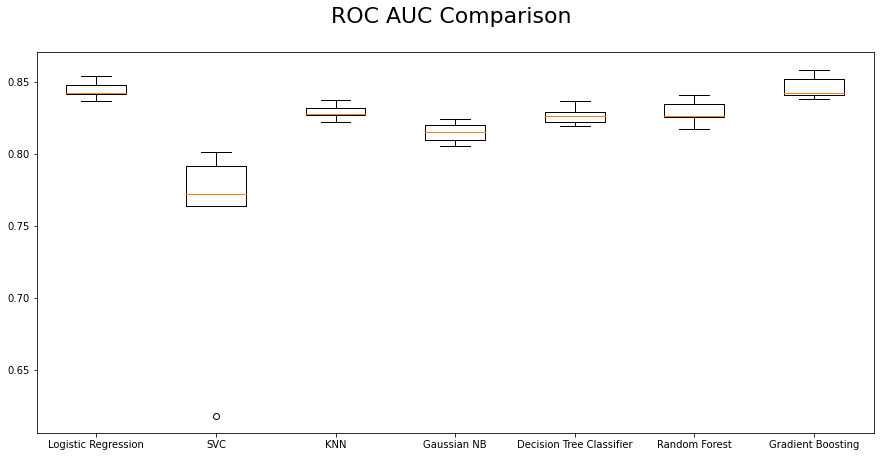

In [58]:
model_results.sort_values(by=['ROC AUC Mean'], ascending=False)
fig = plt.figure(figsize=(15, 7))
ax = fig.add_subplot(111)
plt.boxplot(auc_results)
ax.set_xticklabels(names)


#plt.ylabel('ROC AUC Score\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
#plt.xlabel('\n Baseline Classification Algorithms\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('ROC AUC Comparison \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()


In [59]:
#normalising
norm=MinMaxScaler()

X_train_norm = pd.DataFrame(norm.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

X_test_norm = pd.DataFrame(norm.transform(X_test), columns=X_test.columns, index=X_test.index)


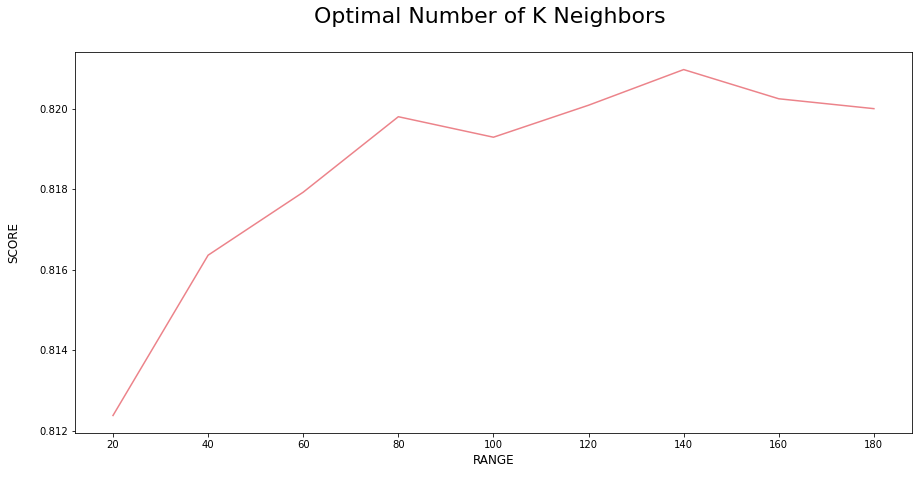

In [60]:
#Identify optimal number of K neighbors for KNN Model:


score_array = []
for each in range(20,200,20):
    knn_loop = KNeighborsClassifier(n_neighbors = each, metric = 'minkowski', p = 2,  n_jobs=6) 
    knn_loop.fit(X_train_norm,y_train)
    score_array.append(cross_val_score( knn_loop, X_train_norm, y_train, cv=2, scoring='roc_auc').mean())

fig = plt.figure(figsize=(15, 7))
plt.plot(range(20,200,20),score_array, color = '#ec838a')


plt.ylabel('SCORE\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('RANGE\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('Optimal Number of K Neighbors \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()

#optimal number of K neigbors = 80


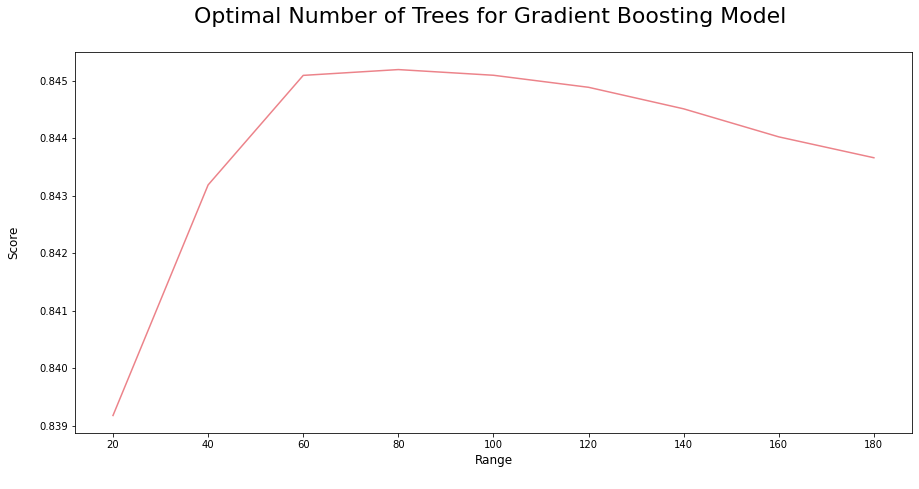

In [61]:
#Identify optimal number of trees for Gradient Boosting Model:

 
score_array = []
for each in range(20,200,20):
    gr_loop = GradientBoostingClassifier(n_estimators = each, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500) 
    gr_loop.fit(X_train,y_train)
    #score_array.append(gr_loop.score(X_test,y_test))
    score_array.append(cross_val_score( gr_loop, X_train, y_train, cv=2, scoring='roc_auc').mean())

 
fig = plt.figure(figsize=(15, 7))
plt.plot(range(20,200,20),score_array, color = '#ec838a')


plt.ylabel('Score\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('Range\n',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.title('Optimal Number of Trees for Gradient Boosting Model \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
#plt.legend(loc='top right', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")


plt.show()
 
 
#Optimal number of decision trees =60


In [62]:
#--Logistic Regression-----------------

# Fitting Logistic Regression to the Training set 
classifier_LR = LogisticRegression(solver='liblinear', random_state = 0,
                                                         class_weight='balanced',  n_jobs=6)
classifier_LR.fit(X_train, y_train)

# Predicting the Test set results
y_pred_LR_tr = classifier_LR.predict(X_train)
y_pred_LR_tr_Pr = classifier_LR.predict_proba(X_train)[:, 1]


#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_LR_tr_Pr )
acc = accuracy_score(y_train, y_pred_LR_tr )
prec = precision_score(y_train, y_pred_LR_tr )
rec = recall_score(y_train, y_pred_LR_tr )
f1 = f1_score(y_train, y_pred_LR_tr )
f2 = fbeta_score(y_train, y_pred_LR_tr, beta=2.0)

results = pd.DataFrame([['Logistic Regression', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

# Test part
y_pred_LR_test = classifier_LR.predict(X_test)
y_pred_LR_test_Pr = classifier_LR.predict_proba(X_test)[:, 1]


roc_auc=roc_auc_score(y_test, y_pred_LR_test_Pr )
acc = accuracy_score(y_test, y_pred_LR_test )
prec = precision_score(y_test, y_pred_LR_test )
rec = recall_score(y_test, y_pred_LR_test )
f1 = f1_score(y_test, y_pred_LR_test )
f2 = fbeta_score(y_test, y_pred_LR_test, beta=2.0)

model_results = pd.DataFrame([['Logistic Regression', 'Test', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)
results

C:\Users\User\Desktop\sample_project\env\lib\site-packages\sklearn\linear_model\_logistic.py:1523: UserWarning: 'n_jobs' > 1 does not have any effect when 'solver' is set to 'liblinear'. Got 'n_jobs' = 6.
  warnings.warn(
C:\Users\User\AppData\Local\Temp\ipykernel_3340\2094720173.py:41: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,Logistic Regression,Train,0.847700,0.749734,0.522151,0.802379,0.632621,0.724603
1,Logistic Regression,Test,0.848053,0.753016,0.506897,0.825843,0.628205,0.733533


In [63]:
#--Gradient Boosting Classifier-----------------

# Fitting Logistic Regression to the Training set 
classifier_GR = GradientBoostingClassifier(n_estimators = 60, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500)
classifier_GR.fit(X_train, y_train)

# Predicting the Test set results
y_pred_GR_tr = classifier_GR.predict(X_train)
y_pred_GR_tr_Pr = classifier_GR.predict_proba(X_train)[:, 1]

#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_GR_tr_Pr )
acc = accuracy_score(y_train, y_pred_GR_tr )
prec = precision_score(y_train, y_pred_GR_tr )
rec = recall_score(y_train, y_pred_GR_tr )
f1 = f1_score(y_train, y_pred_GR_tr )
f2 = fbeta_score(y_train, y_pred_GR_tr, beta=2.0)

model_results = pd.DataFrame([['GBM', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

# Test part
y_pred_GR_test = classifier_GR.predict(X_test)
y_pred_GR_test_Pr = classifier_GR.predict_proba(X_test)[:, 1]


roc_auc=roc_auc_score(y_test, y_pred_GR_test_Pr )
acc = accuracy_score(y_test, y_pred_GR_test )
prec = precision_score(y_test, y_pred_GR_test )
rec = recall_score(y_test, y_pred_GR_test )
f1 = f1_score(y_test, y_pred_GR_test )
f2 = fbeta_score(y_test, y_pred_GR_test, beta=2.0)

model_results = pd.DataFrame([['GBM', 'Test', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)
results

C:\Users\User\AppData\Local\Temp\ipykernel_3340\3375703725.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,Logistic Regression,Train,0.847700,0.749734,0.522151,0.802379,0.632621,0.724603
1,Logistic Regression,Test,0.848053,0.753016,0.506897,0.825843,0.628205,0.733533
2,GBM,Test,0.847582,0.809084,0.652632,0.522472,0.580343,0.544178


In [64]:
#--KNeighbors-----------------

# Fitting Logistic Regression to the Training set 
classifier_KNN = KNeighborsClassifier(n_neighbors = 80, metric = 'minkowski', p = 2,  n_jobs=6) 
classifier_KNN.fit(X_train, y_train)

# Predicting the Test set results
y_pred_KNN_tr = classifier_KNN.predict(X_train)
y_pred_KNN_tr_Pr = classifier_KNN.predict_proba(X_train)[:, 1]


#Evaluate results

# Train part
roc_auc=roc_auc_score(y_train, y_pred_KNN_tr_Pr )
acc = accuracy_score(y_train, y_pred_KNN_tr )
prec = precision_score(y_train, y_pred_KNN_tr )
rec = recall_score(y_train, y_pred_KNN_tr )
f1 = f1_score(y_train, y_pred_KNN_tr )
f2 = fbeta_score(y_train, y_pred_KNN_tr, beta=2.0)

model_results = pd.DataFrame([['K-NN', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])


# test part
y_pred_KNN_test = classifier_KNN.predict(X_test)
y_pred_KNN_test_Pr = classifier_KNN.predict_proba(X_test)[:, 1]


roc_auc=roc_auc_score(y_test, y_pred_KNN_test_Pr )
acc = accuracy_score(y_test, y_pred_KNN_test )
prec = precision_score(y_test, y_pred_KNN_test )
rec = recall_score(y_test, y_pred_KNN_test )
f1 = f1_score(y_test, y_pred_KNN_test )
f2 = fbeta_score(y_test, y_pred_KNN_test, beta=2.0)

model_results = pd.DataFrame([['K-NN', 'Test', roc_auc, acc, prec, rec, f1, f2]],
               columns = ['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)
results

C:\Users\User\AppData\Local\Temp\ipykernel_3340\3012462214.py:41: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,Logistic Regression,Train,0.847700,0.749734,0.522151,0.802379,0.632621,0.724603
1,Logistic Regression,Test,0.848053,0.753016,0.506897,0.825843,0.628205,0.733533
2,GBM,Test,0.847582,0.809084,0.652632,0.522472,0.580343,0.544178
3,K-NN,Test,0.827377,0.796309,0.612378,0.528090,0.567119,0.543039


In [65]:
# Fitting XGBoost to the Training set
classifier_XGB = XGBClassifier(n_estimators=60, max_depth=5, random_state=1)
classifier_XGB.fit(X_train, y_train)

# Predicting the Test set results
y_pred_XGB_tr = classifier_XGB.predict(X_train)
y_pred_XGB_tr_Pr = classifier_XGB.predict_proba(X_train)[:, 1]

# Evaluate results

# Train part
roc_auc = roc_auc_score(y_train, y_pred_XGB_tr_Pr)
acc = accuracy_score(y_train, y_pred_XGB_tr)
prec = precision_score(y_train, y_pred_XGB_tr)
rec = recall_score(y_train, y_pred_XGB_tr)
f1 = f1_score(y_train, y_pred_XGB_tr)
f2 = fbeta_score(y_train, y_pred_XGB_tr, beta=2.0)

model_results = pd.DataFrame([['XGBoost', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns=['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)

# Test part
y_pred_XGB_test = classifier_XGB.predict(X_test)
y_pred_XGB_test_Pr = classifier_XGB.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_XGB_test_Pr)
acc = accuracy_score(y_test, y_pred_XGB_test)
prec = precision_score(y_test, y_pred_XGB_test)
rec = recall_score(y_test, y_pred_XGB_test)
f1 = f1_score(y_test, y_pred_XGB_test)
f2 = fbeta_score(y_test, y_pred_XGB_test, beta=2.0)

model_results = pd.DataFrame([['XGBoost', 'Test', roc_auc, acc, prec, rec, f1, f2]],
               columns=['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)
results

C:\Users\User\AppData\Local\Temp\ipykernel_3340\2314424932.py:22: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index=True)
C:\Users\User\AppData\Local\Temp\ipykernel_3340\2314424932.py:38: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index=True)


,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,Logistic Regression,Train,0.847700,0.749734,0.522151,0.802379,0.632621,0.724603
1,Logistic Regression,Test,0.848053,0.753016,0.506897,0.825843,0.628205,0.733533
2,GBM,Test,0.847582,0.809084,0.652632,0.522472,0.580343,0.544178
3,K-NN,Test,0.827377,0.796309,0.612378,0.528090,0.567119,0.543039
4,XGBoost,Train,0.936300,0.867057,0.793846,0.682089,0.733736,0.701850
5,XGBoost,Test,0.824824,0.776437,0.550617,0.626404,0.586071,0.609623


In [66]:
# Fitting CatBoost to the Training set
classifier_CB = CatBoostClassifier(iterations=60, depth=5, random_seed=1, verbose=0)
classifier_CB.fit(X_train, y_train)

# Predicting the Test set results
y_pred_CB_tr = classifier_CB.predict(X_train)
y_pred_CB_tr_Pr = classifier_CB.predict_proba(X_train)[:, 1]

# Evaluate results

# Train part
roc_auc = roc_auc_score(y_train, y_pred_CB_tr_Pr)
acc = accuracy_score(y_train, y_pred_CB_tr)
prec = precision_score(y_train, y_pred_CB_tr)
rec = recall_score(y_train, y_pred_CB_tr)
f1 = f1_score(y_train, y_pred_CB_tr)
f2 = fbeta_score(y_train, y_pred_CB_tr, beta=2.0)

model_results = pd.DataFrame([['CatBoost', 'Train', roc_auc, acc, prec, rec, f1, f2]],
               columns=['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)

# Validation part
y_pred_CB_test = classifier_CB.predict(X_test)
y_pred_CB_test_Pr = classifier_CB.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_CB_test_Pr)
acc = accuracy_score(y_test, y_pred_CB_test)
prec = precision_score(y_test, y_pred_CB_test)
rec = recall_score(y_test, y_pred_CB_test)
f1 = f1_score(y_test, y_pred_CB_test)
f2 = fbeta_score(y_test, y_pred_CB_test, beta=2.0)

model_results = pd.DataFrame([['CatBoost', 'Test', roc_auc, acc, prec, rec, f1, f2]],
               columns=['Model', 'Dataset', 'AUC', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'F2 Score'])

results = pd.concat([results, model_results], ignore_index=True)
results


C:\Users\User\AppData\Local\Temp\ipykernel_3340\1506564652.py:22: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index=True)
C:\Users\User\AppData\Local\Temp\ipykernel_3340\1506564652.py:38: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index=True)


,Model,Dataset,AUC,Accuracy,Precision,Recall,F1 Score,F2 Score
0,Logistic Regression,Train,0.847700,0.749734,0.522151,0.802379,0.632621,0.724603
1,Logistic Regression,Test,0.848053,0.753016,0.506897,0.825843,0.628205,0.733533
2,GBM,Test,0.847582,0.809084,0.652632,0.522472,0.580343,0.544178
3,K-NN,Test,0.827377,0.796309,0.612378,0.528090,0.567119,0.543039
4,XGBoost,Train,0.936300,0.867057,0.793846,0.682089,0.733736,0.701850
5,XGBoost,Test,0.824824,0.776437,0.550617,0.626404,0.586071,0.609623
6,CatBoost,Train,0.883622,0.828896,0.727423,0.580304,0.645588,0.604766
7,CatBoost,Test,0.846514,0.813343,0.651466,0.561798,0.603318,0.577701


In [67]:
def calculate_lift(y_true, y_pred_prob, num_bins):
    # Sorting instances by prediction probability
    sorted_indices = np.argsort(y_pred_prob)[::-1]
    y_true = y_true[sorted_indices]

    # Number of instances in the entire dataset
    n_total = len(y_true)
    # Number of positive instances in the entire dataset
    n_positives_total = np.sum(y_true)
    # Size of each bin
    bin_size = n_total // num_bins

    if n_positives_total == 0:
        return [np.nan] * num_bins, [(i*100/num_bins, (i+1)*100/num_bins) for i in range(num_bins)]

    lift_values = []
    percentages = []
    for i in range(num_bins):
        start_idx = i * bin_size
        end_idx = (i + 1) * bin_size if i != (num_bins - 1) else n_total
        bin_labels = y_true[start_idx:end_idx]

        # Number of positive instances in the bin
        n_positives_bin = np.sum(bin_labels)

        # Calculating the lift for the bin
        expected_positives_bin = n_positives_total * bin_size / n_total
        lift = n_positives_bin / expected_positives_bin if expected_positives_bin > 0 else np.nan
        lift_values.append(lift)

        # Adding the percentage range for this bin
        percentages.append((i*100/num_bins, (i+1)*100/num_bins))

    return lift_values, percentages


In [68]:
# List of bin numbers
bin_numbers = [5, 10, 20]

# Iterate through the bin numbers
for num_bins in bin_numbers:
    lift_values_KNN, percentages = calculate_lift(np.array(y_test), y_pred_KNN_test_Pr, num_bins)
    lift_values_GRB, percentages = calculate_lift(np.array(y_test), y_pred_GR_test_Pr, num_bins)
    lift_values_LRegr, percentages = calculate_lift(np.array(y_test), y_pred_LR_test_Pr, num_bins)
    
    


    lift_df = pd.DataFrame({
        'Lift_LRegr': lift_values_LRegr,
        'Lift_KNN': lift_values_KNN,
        'Lift_GRB': lift_values_GRB,                
        'Percentage': [f'{p[0]} - {p[1]}%' for p in percentages]
    })

    # Apply styling
    styled_lift = lift_df.style.background_gradient(cmap='coolwarm').format(precision=2)

    # Display the result
    print(f"Results for {num_bins} bins:")
    display(styled_lift)


Results for 5 bins:


C:\Users\User\AppData\Local\Temp\ipykernel_3340\1472182909.py:21: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  styled_lift = lift_df.style.background_gradient(cmap='coolwarm').set_precision(2)


,Lift_LRegr,Lift_KNN,Lift_GRB,Percentage
0,2.62,2.42,2.62,0.0 - 20.0%
1,1.44,1.58,1.34,20.0 - 40.0%
2,0.62,0.58,0.75,40.0 - 60.0%
3,0.24,0.30,0.23,60.0 - 80.0%
4,0.10,0.14,0.08,80.0 - 100.0%


Results for 10 bins:


,Lift_LRegr,Lift_KNN,Lift_GRB,Percentage
0,3.02,2.77,3.05,0.0 - 10.0%
1,2.21,2.09,2.18,10.0 - 20.0%
2,1.55,1.87,1.70,20.0 - 30.0%
3,1.33,1.27,0.96,30.0 - 40.0%
4,0.82,0.74,1.07,40.0 - 50.0%
5,0.45,0.45,0.48,50.0 - 60.0%
6,0.37,0.40,0.25,60.0 - 70.0%
7,0.11,0.20,0.20,70.0 - 80.0%
8,0.08,0.14,0.11,80.0 - 90.0%
9,0.11,0.14,0.06,90.0 - 100.0%


Results for 20 bins:


,Lift_LRegr,Lift_KNN,Lift_GRB,Percentage
0,3.17,2.83,3.28,0.0 - 5.0%
1,2.88,2.71,2.83,5.0 - 10.0%
2,2.37,1.98,2.09,10.0 - 15.0%
3,2.04,2.21,2.26,15.0 - 20.0%
4,1.64,1.98,1.87,20.0 - 25.0%
5,1.47,1.75,1.53,25.0 - 30.0%
6,1.53,1.41,1.07,30.0 - 35.0%
7,1.13,1.13,0.85,35.0 - 40.0%
8,1.02,0.79,1.19,40.0 - 45.0%
9,0.62,0.68,0.96,45.0 - 50.0%


In [69]:
# Gradient Boosting
feature_importances_GR = classifier_GR.feature_importances_
feature_importance = pd.DataFrame({'Features':classifier_GR.feature_names_in_,
                                  'Feature Importance':classifier_GR.feature_importances_})
feature_importance.sort_values(by='Feature Importance',ascending=False,inplace=True)
feature_importance

,Features,Feature Importance
14,Contract,0.419990
4,tenure,0.170458
17,MonthlyCharges,0.118190
8,OnlineSecurity,0.098912
11,TechSupport,0.067137
16,PaymentMethod,0.041970
18,TotalCharges,0.025926
15,PaperlessBilling,0.014090
7,InternetService,0.013483
9,OnlineBackup,0.008577


In [70]:
Selected_features = feature_importance[(feature_importance['Feature Importance'] >= 0.09)] # Usually >=0.1, now because of OnlineSecurity

In [71]:
Selected_features

,Features,Feature Importance
14,Contract,0.419990
4,tenure,0.170458
17,MonthlyCharges,0.118190
8,OnlineSecurity,0.098912


In [72]:
#shortlist of important features
shortlist=Selected_features.Features.tolist()


In [73]:
GRB = GradientBoostingClassifier(n_estimators = 60, criterion = 'friedman_mse', random_state = 1, max_depth=5, min_samples_leaf=500)
GRB.fit(X_train[shortlist], y_train)


GradientBoostingClassifier(max_depth=5, min_samples_leaf=500, n_estimators=60,
                           random_state=1)

In [74]:
def scores (model, name):
    
    # Predicting the Test set results
    y_pred_tr = model.predict(X_train[shortlist])
    y_pred_tr_Pr = model.predict_proba(X_train[shortlist])[:, 1]

    #Evaluate results

    # Train part
    roc_auc=roc_auc_score(y_train, y_pred_tr_Pr )
    prec = precision_score(y_train, y_pred_tr )
    rec = recall_score(y_train, y_pred_tr )

    results = pd.DataFrame([[name, 'Train', roc_auc,  prec, rec]],
                   columns = ['Model', 'Dataset', 'AUC',  'Precision', 'Recall'])


    # Test part
    y_pred_test = model.predict(X_test[shortlist])
    y_pred_test_Pr = model.predict_proba(X_test[shortlist])[:, 1]


    roc_auc=roc_auc_score(y_test, y_pred_test_Pr )
    prec = precision_score(y_test, y_pred_test )
    rec = recall_score(y_test, y_pred_test )

    model_results = pd.DataFrame([[name, 'Test', roc_auc,  prec, rec]],
                   columns = ['Model', 'Dataset', 'AUC',  'Precision', 'Recall'])

    results = pd.concat([results, model_results], ignore_index=True)
    return(results)


In [75]:
GRB_scores=scores (GRB, 'GRB')
GRB_scores

C:\Users\User\AppData\Local\Temp\ipykernel_3340\668165865.py:30: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  results = results.append(model_results, ignore_index = True)


,Model,Dataset,AUC,Precision,Recall
0,GRB,Train,0.851211,0.668333,0.530073
1,GRB,Test,0.839976,0.628866,0.514045


In [76]:
from sklearn.model_selection import  KFold, ParameterGrid


# Define the GradientBoostingClassifier
clf = GradientBoostingClassifier()

# Define the hyperparameters and their possible values
param_grid = {
    'n_estimators': [50, 60, 90],
   'learning_rate': [ 0.05, 0.1, 0.5],
   'max_depth': [4, 5],
   'min_samples_split': [1000, 300],
    'min_samples_leaf':[300,500]
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []



In [77]:
for params in ParameterGrid(param_grid):
    train_aucs, test_aucs, train_precisions, test_precisions, train_recalls, test_recalls = [], [], [], [], [], []
    for train_index, test_index in kf.split(X[shortlist], y):
        X_train_fold, X_test_fold = X[shortlist].iloc[train_index], X[shortlist].iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

        clf.set_params(**params)
        clf.fit(X_train_fold, y_train_fold)

        y_train_pred = clf.predict_proba(X_train_fold)[:, 1]
        y_test_pred = clf.predict_proba(X_test_fold)[:, 1]

        train_auc = roc_auc_score(y_train_fold, y_train_pred)
        test_auc = roc_auc_score(y_test_fold, y_test_pred)

        train_precision = precision_score(y_train_fold, (y_train_pred > 0.5).astype(int))
        test_precision = precision_score(y_test_fold, (y_test_pred > 0.5).astype(int))

        train_recall = recall_score(y_train_fold, (y_train_pred > 0.5).astype(int))
        test_recall = recall_score(y_test_fold, (y_test_pred > 0.5).astype(int))

        train_aucs.append(train_auc)
        test_aucs.append(test_auc)
        train_precisions.append(train_precision)
        test_precisions.append(test_precision)
        train_recalls.append(train_recall)
        test_recalls.append(test_recall)
        
    results_dict = {
        "Classifier": 'GradientBoostingClassifier',
        "Train AUC-ROC": np.mean(train_aucs),
        "Test AUC-ROC": np.mean(test_aucs),
        "AUC_ROC_STD_on_Test": np.std(test_aucs),
        "Train Precision": np.mean(train_precisions),
        "Test Precision": np.mean(test_precisions),
        "Train Recall": np.mean(train_recalls),
        "Test Recall": np.mean(test_recalls)
    }
    
    # Add the hyperparameters to the results dictionary
    for key, value in params.items():
        results_dict[key] = value

    results.append(results_dict)

    
    print(len(results))

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72


,Classifier,Train AUC-ROC,Test AUC-ROC,AUC_ROC_STD_on_Test,Train Precision,Test Precision,Train Recall,Test Recall,learning_rate,max_depth,min_samples_leaf,min_samples_split,n_estimators
0,GradientBoostingClassifier,0.848821,0.838698,0.011171,0.690925,0.677724,0.450440,0.435363,0.05,4,300,1000,50
1,GradientBoostingClassifier,0.850128,0.839318,0.011204,0.686032,0.669198,0.468596,0.453802,0.05,4,300,1000,60
2,GradientBoostingClassifier,0.852413,0.840357,0.010768,0.674252,0.655966,0.509468,0.497909,0.05,4,300,1000,90
3,GradientBoostingClassifier,0.850320,0.839106,0.011579,0.692672,0.668887,0.454653,0.438917,0.05,4,300,300,50
4,GradientBoostingClassifier,0.851439,0.839552,0.011722,0.688504,0.666502,0.470320,0.454902,0.05,4,300,300,60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,GradientBoostingClassifier,0.864408,0.837132,0.012681,0.698411,0.657522,0.533653,0.500802,0.50,5,500,1000,60
68,GradientBoostingClassifier,0.869415,0.836018,0.012740,0.704264,0.650608,0.544641,0.502297,0.50,5,500,1000,90
69,GradientBoostingClassifier,0.862440,0.837387,0.012564,0.694298,0.656337,0.532187,0.502191,0.50,5,500,300,50
70,GradientBoostingClassifier,0.864408,0.837132,0.012681,0.698411,0.657522,0.533653,0.500802,0.50,5,500,300,60


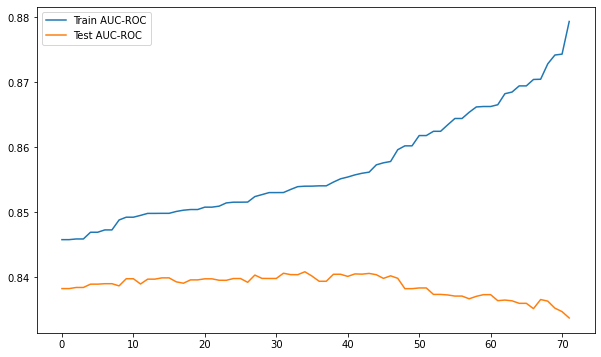

In [78]:
# Convert results to DataFrame
GRB_results = pd.DataFrame(results)

GRB_results.sort_values('Train AUC-ROC')[['Train AUC-ROC', 'Test AUC-ROC']].reset_index(drop=True).plot(figsize=(10,6))
GRB_results


In [84]:
# Add Shap values 
!pip install -q shap

import shap

model = GradientBoostingClassifier(n_estimators=90,min_samples_split=1000,min_samples_leaf=300,max_depth=4,learning_rate=0.5)
model.fit(X_train[shortlist], y_train)

# Initialize the SHAP TreeExplainer
explainer = shap.TreeExplainer(model)

# Compute SHAP values for the test set
shap_values = explainer.shap_values(X_test[shortlist])

# Summary plot
shap.summary_plot(shap_values, X_test[shortlist])
plt.show()

In [90]:
# Initialize JS visualization for SHAP
shap.initjs()
# Force plot for a single prediction
shap.force_plot(explainer.expected_value, shap_values[0], X_test[shortlist].iloc[0])